# 11 · Riverside vegetation: did willows recover after wolves, and does water matter more than elk?

**Person 2 (Leora).** The plant link of the trophic cascade. Ripple & Beschta's cascade claim is about streamside willows, so we test it where the claim is made: Landsat NDVI (greenness) along three northern-range streams, each compared with a nearby slope that shares the same weather.

| Section | Question | Methods |
|---|---|---|
| 0 | Data and cleaning | handling partial rows, quality filter |
| 1 | What do the series look like? | seasonal cycle, sensor-era check |
| 2 | Did the riverside get greener than the slopes after wolves returned? (Q1) | riverside − slope difference, Mann–Kendall, intervention regression, break search, STL |
| 3 | Does water limit willows more than elk do? (Q6) | regression on summer low flow, elk, bison; first-difference check; Granger causality (pairwise and VAR); residual white-noise checks |
| 4 | Does spring green-up follow snowmelt? (Q3) | double-logistic curves, correlation, trend |
| 5 | What did the 2022 flood do to the riverside? | before/after comparison |
| 6 | Summary | |

**The key design:** for each stream, *riverside minus slope* NDVI on the same image date. Weather, drought, sensor changes and haze hit both areas alike, so they largely cancel; what is left is what is special about the riverside (willows, water, flooding, browsing).

In [1]:
import csv
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymannkendall as mk
import ruptures as rpt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy.optimize import curve_fit
from statsmodels.tsa.seasonal import STL

warnings.filterwarnings("ignore")
pd.set_option("display.width", 140)
plt.rcParams["figure.dpi"] = 110

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW, PROC = ROOT / "data" / "raw", ROOT / "data" / "processed"
FIG, TAB = ROOT / "reports" / "figures", ROOT / "reports" / "tables"
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)
PAIRS = ["Lamar", "Soda Butte", "Blacktail"]
COL = {"Lamar": "C0", "Soda Butte": "C1", "Blacktail": "C2"}

def save(fig, name):
    fig.tight_layout(); fig.savefig(FIG / f"P2_{name}.png", dpi=200)

def trend(s, label):
    s = s.dropna()
    o, h = mk.original_test(s.values), mk.hamed_rao_modification_test(s.values)
    return {"series": label, "years": f"{s.index.min()}–{s.index.max()}", "n": len(s),
            "Sen slope per decade": round(10 * o.slope, 4), "MK p": round(o.p, 4),
            "MK p (autocorr-corrected)": round(h.p, 4), "direction": o.trend}

## 0. Data and cleaning

Two Climate Engine exports (Landsat 5/7/8/9 surface reflectance, NDVI, 30 m, mean over each polygon, every image 1984-01-01 to 2026-11-16). The polygon corner coordinates are in each file's header, so the areas are fully documented.

| File | Polygon 1 | Polygon 2 | Polygon 3 | Polygon 4 |
|---|---|---|---|---|
| `ndvi_lamar_sodabutte.csv` | Lamar riverside | Lamar slope | Soda Butte riverside | Soda Butte slope |
| `ndvi_blacktail.csv` | Blacktail riverside | Blacktail slope | | |

**Partial rows.** When clouds mask some polygons on a date, the export simply leaves those values out without saying which polygon is missing, so a row with fewer values than polygons cannot be assigned. Only complete rows are used. This loses no information for the paired design, which needs riverside and slope on the same date anyway.

**Quality filter.** NDVI outside −0.2 to 0.95 is treated as an artefact (snow, cloud edges) and dropped.

In [2]:
def load_ce(path, names):
    rows = [r for r in csv.reader(open(path)) if r and r[0][:2] in ("19", "20")]
    full = [r for r in rows if len(r) == len(names) + 1]
    d = pd.DataFrame([[pd.Timestamp(r[0])] + [float(x) for x in r[1:]] for r in full],
                     columns=["date"] + names).set_index("date")
    print(f"{path.name}: {len(rows)} image dates, {len(full)} complete ({len(rows) - len(full)} partial rows dropped)")
    return d

a = load_ce(RAW / "ndvi_lamar_sodabutte.csv", ["Lamar|riverside", "Lamar|slope", "Soda Butte|riverside", "Soda Butte|slope"])
b = load_ce(RAW / "ndvi_blacktail.csv", ["Blacktail|riverside", "Blacktail|slope"])
long = pd.concat([a.stack(), b.stack()]).rename("ndvi").reset_index()
long.columns = ["date", "region", "ndvi"]
long[["pair", "side"]] = long["region"].str.split("|", expand=True)
n0 = len(long)
long = long[long["ndvi"].between(-0.2, 0.95)].copy()
long["year"], long["doy"], long["month"] = long.date.dt.year, long.date.dt.dayofyear, long.date.dt.month
long["OLI_era"] = (long.date >= "2013-04-11").astype(int)      # Landsat 8 launched; its NDVI reads slightly higher
print(f"Quality filter removed {n0 - len(long)} of {n0} values")
long.groupby(["pair", "side"])["ndvi"].describe().round(3)

ndvi_lamar_sodabutte.csv: 1003 image dates, 599 complete (404 partial rows dropped)
ndvi_blacktail.csv: 692 image dates, 590 complete (102 partial rows dropped)
Quality filter removed 0 of 3576 values


count   mean    std    min    25%    50%    75%    max
pair       side                                                             
Blacktail  riverside  590.0  0.394  0.140  0.039  0.294  0.409  0.504  0.698
           slope      590.0  0.334  0.134  0.011  0.236  0.331  0.441  0.718
Lamar      riverside  599.0  0.328  0.119 -0.022  0.253  0.342  0.410  0.662
           slope      599.0  0.380  0.135  0.009  0.283  0.375  0.482  0.746
Soda Butte riverside  599.0  0.343  0.124 -0.086  0.265  0.355  0.439  0.600
           slope      599.0  0.428  0.164 -0.043  0.316  0.426  0.560  0.757

## 1. What the series look like

Every polygon shows the same mountain growing season: near zero under snow, green-up in May–June, a peak in late June–July, drying from August. In Lamar and Soda Butte the riverside reads *lower* than the slope because the riverside polygons include bare gravel bars and water; that is a level difference, and the analysis is about how the difference *changes*.

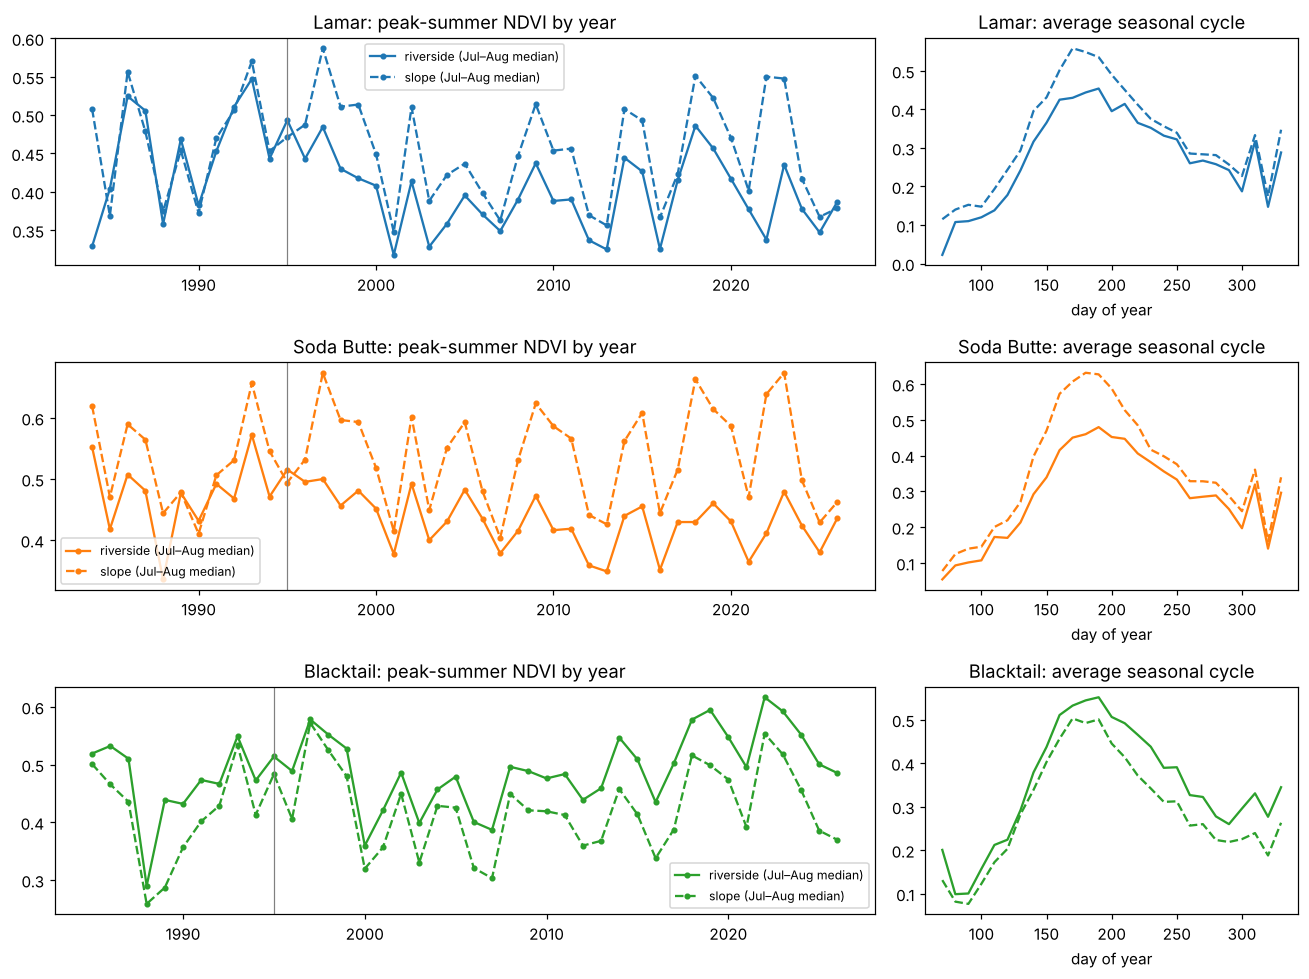

In [3]:
fig, ax = plt.subplots(3, 2, figsize=(12, 9), gridspec_kw={"width_ratios": [2.2, 1]})
for i, p in enumerate(PAIRS):
    for side, ls in [("riverside", "-"), ("slope", "--")]:
        d = long[(long.pair == p) & (long.side == side)]
        gs = d[d.month.isin([7, 8])].groupby("year")["ndvi"].median()
        ax[i, 0].plot(gs.index, gs.values, ls, marker=".", color=COL[p], label=f"{side} (Jul–Aug median)")
        clim = d[d.month.between(3, 11)].groupby((d.doy // 10) * 10)["ndvi"].median()
        ax[i, 1].plot(clim.index, clim.values, ls, color=COL[p], label=side)
    ax[i, 0].axvline(1995, color="0.5", lw=0.8); ax[i, 0].set_title(f"{p}: peak-summer NDVI by year"); ax[i, 0].legend(fontsize=8)
    ax[i, 1].set_title(f"{p}: average seasonal cycle"); ax[i, 1].set_xlabel("day of year")
save(fig, "09_ndvi_overview")

**Sensor check.** Landsat 8 (from 2013) reads NDVI a little higher than Landsat 5/7, which can fake a jump in a single series. If both areas of a pair shift by the same amount, the difference is unaffected. The table compares the step at 2013 in each side and in the difference (annual Jul–Aug medians, controlling for a linear trend).

In [4]:
def annual(side_df):
    return side_df[side_df.month.isin([7, 8])].groupby("year")["ndvi"].median()

paired = long.pivot_table(index=["date", "pair"], columns="side", values="ndvi").dropna().reset_index()
paired["diff"] = paired["riverside"] - paired["slope"]
paired["year"], paired["month"], paired["doy"] = paired.date.dt.year, paired.date.dt.month, paired.date.dt.dayofyear
summer = paired[paired.month.isin([7, 8])]
ann = summer.groupby(["pair", "year"]).agg(riverside=("riverside", "median"), slope=("slope", "median"),
                                          diff=("diff", "median"), n_images=("diff", "size")).reset_index()
ann.to_csv(PROC / "ndvi_annual_peak_summer.csv", index=False)

rows = []
for p in PAIRS:
    d = ann[ann.pair == p].set_index("year")
    X = sm.add_constant(pd.DataFrame({"t": d.index - 2000, "OLI": (d.index >= 2013).astype(int)}, index=d.index))
    for col in ["riverside", "slope", "diff"]:
        r = sm.OLS(d[col], X).fit()
        rows.append({"pair": p, "series": col, "step at 2013": round(r.params["OLI"], 3), "p": round(r.pvalues["OLI"], 3)})
pd.DataFrame(rows).pivot(index="pair", columns="series", values="step at 2013")

series,diff,riverside,slope
pair,,,
Blacktail,0.027,0.071,0.041
Lamar,0.007,0.046,0.033
Soda Butte,0.003,0.012,0.014


## 2. Did the riverside get greener than the slopes after wolves returned? (Q1)

The annual statistic is the **median of riverside − slope** over all July–August images of each year (median, so one hazy image cannot dominate). If the cascade worked, this difference should rise after wolves returned in 1995, with a lag of a few years for willows to grow.

Tests, all on that annual difference:

1. **Mann–Kendall + Sen's slope** for 1984–2026, 1984–1994 and 1996–2026.
2. **Intervention regression** (the midsem dummy-regression approach): $d_y = a + b\,t + c\,\text{post}_{1995} + e\,(t-1995)\,\text{post}_{1995}$. A cascade predicts $c>0$ or $e>0$. Newey–West standard errors for autocorrelation.
3. **Break search:** let the data choose up to 3 shifts in the mean (exact dynamic programming, at least 5 years per segment, number of breaks chosen by BIC, zero allowed).

,years,n,Sen slope per decade,MK p,MK p (autocorr-corrected),direction
series,,,,,,
Lamar: 1984–2026,1984–2026,43,-0.0136,0.0180,0.0180,decreasing
Lamar: 1984–1994,1984–1994,11,-0.0290,0.5334,NaN,no trend
Lamar: 1996–2026,1996–2026,31,0.0077,0.2767,0.2767,no trend
Soda Butte: 1984–2026,1984–2026,43,-0.0273,0.0009,0.0091,decreasing
Soda Butte: 1984–1994,1984–1994,11,-0.0072,0.8763,0.8763,no trend
Soda Butte: 1996–2026,1996–2026,31,-0.0157,0.3242,0.3242,no trend
Blacktail: 1984–2026,1985–2026,42,0.0176,0.0000,0.0000,increasing
Blacktail: 1984–1994,1985–1994,10,-0.0087,0.5915,0.5915,no trend
Blacktail: 1996–2026,1996–2026,31,0.0255,0.0000,0.0000,increasing


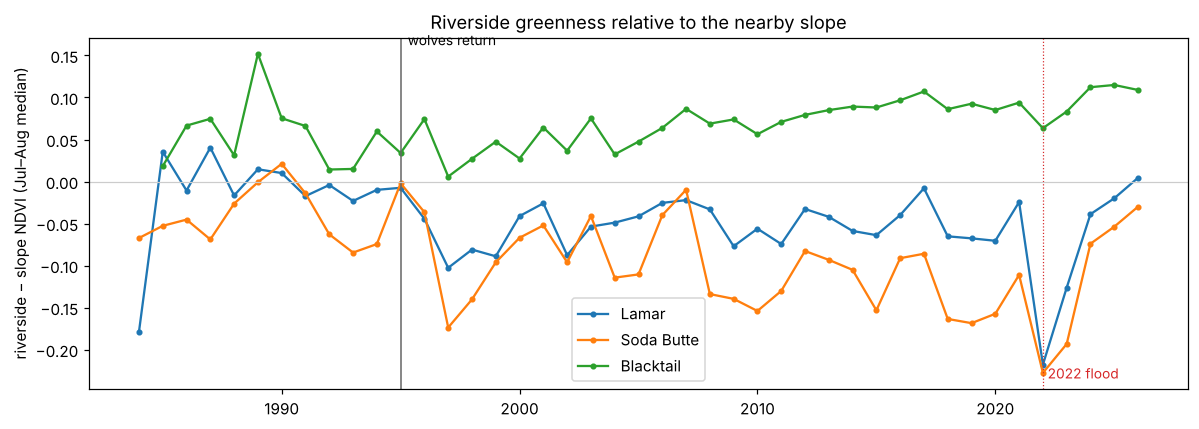

In [5]:
fig, ax = plt.subplots(figsize=(11, 4))
for p in PAIRS:
    d = ann[ann.pair == p]
    ax.plot(d.year, d["diff"], "o-", ms=3, color=COL[p], label=p)
ax.axvline(1995, color="0.4", lw=1); ax.text(1995.3, ax.get_ylim()[1] * 0.95, "wolves return", fontsize=9)
ax.axvline(2022, color="C3", lw=0.8, ls=":"); ax.text(2022.2, ax.get_ylim()[0] * 0.95, "2022 flood", fontsize=9, color="C3")
ax.axhline(0, color="0.8", lw=0.8)
ax.set_ylabel("riverside − slope NDVI (Jul–Aug median)"); ax.legend(); ax.set_title("Riverside greenness relative to the nearby slope")
save(fig, "10_riverside_minus_slope")

rows = []
for p in PAIRS:
    s = ann[ann.pair == p].set_index("year")["diff"]
    rows += [trend(s, f"{p}: 1984–2026"), trend(s.loc[:1994], f"{p}: 1984–1994"), trend(s.loc[1996:], f"{p}: 1996–2026")]
veg_trends = pd.DataFrame(rows).set_index("series")
veg_trends.to_csv(TAB / "P2_veg_diff_trends.csv")
veg_trends

In [6]:
def intervention(d):
    d = d.assign(t=d.year - 1995, post=(d.year >= 1995).astype(int))
    d["ramp"] = d["t"] * d["post"]
    return smf.ols("diff ~ t + post + ramp", data=d).fit(cov_type="HAC", cov_kwds={"maxlags": 2})

rows = []
for p in PAIRS + ["pooled (pair effects)"]:
    if p.startswith("pooled"):
        d = ann.assign(t=ann.year - 1995, post=(ann.year >= 1995).astype(int))
        d["ramp"] = d["t"] * d["post"]
        r = smf.ols("diff ~ C(pair) + t + post + ramp", data=d).fit(cov_type="HAC", cov_kwds={"maxlags": 2})
    else:
        r = intervention(ann[ann.pair == p])
    for term, lab in [("t", "pre-1995 trend / yr"), ("post", "step at 1995"), ("ramp", "change in trend after 1995 / yr")]:
        rows.append({"pair": p, "term": lab, "coef": round(r.params[term], 4),
                     "CI low": round(r.conf_int().loc[term, 0], 4), "CI high": round(r.conf_int().loc[term, 1], 4),
                     "p": round(r.pvalues[term], 3), "n": int(r.nobs)})
interv = pd.DataFrame(rows)
interv.to_csv(TAB / "P2_veg_intervention.csv", index=False)
interv

,pair,term,coef,CI low,CI high,p,n
0,Lamar,pre-1995 trend / yr,0.0049,-0.0063,0.0162,0.391,43
1,Lamar,step at 1995,-0.0661,-0.1271,-0.0051,0.034,43
2,Lamar,change in trend after 1995 / yr,-0.0052,-0.0166,0.0061,0.368,43
3,Soda Butte,pre-1995 trend / yr,-0.0005,-0.0069,0.0058,0.869,43
4,Soda Butte,step at 1995,-0.0299,-0.1036,0.0438,0.427,43
5,Soda Butte,change in trend after 1995 / yr,-0.0012,-0.0078,0.0053,0.709,43
6,Blacktail,pre-1995 trend / yr,-0.0016,-0.0077,0.0046,0.611,42
7,Blacktail,step at 1995,-0.0140,-0.0561,0.0281,0.514,42
8,Blacktail,change in trend after 1995 / yr,0.0040,-0.0022,0.0102,0.210,42
9,pooled (pair effects),pre-1995 trend / yr,0.0006,-0.0059,0.0071,0.856,128


**Sensor robustness.** The sensor check in section 1 showed the 2013 Landsat-8 step is not identical for riverside and slope at Blacktail (+0.07 vs +0.04), so part of a rising Blacktail difference could be a sensor artefact. Two checks: add a 2013 sensor dummy to the intervention model, and test the trend *within* each sensor era separately (Landsat 5/7 1996–2012; Landsat 8/9 2013–2026), where no sensor change can create a trend.

In [7]:
rows = []
for p in PAIRS:
    d = ann[ann.pair == p].assign(t=lambda x: x.year - 1995, post=lambda x: (x.year >= 1995).astype(int),
                                  OLI=lambda x: (x.year >= 2013).astype(int))
    d["ramp"] = d["t"] * d["post"]
    r = smf.ols("diff ~ t + post + ramp + OLI", data=d).fit(cov_type="HAC", cov_kwds={"maxlags": 2})
    s = d.set_index("year")["diff"]
    t1, t2 = mk.original_test(s.loc[1996:2012].values), mk.original_test(s.loc[2013:].values)
    rows.append({"pair": p, "step at 1995 (with sensor dummy)": f"{r.params['post']:+.3f} (p={r.pvalues['post']:.2f})",
                 "trend change after 1995 /yr": f"{r.params['ramp']:+.4f} (p={r.pvalues['ramp']:.2f})",
                 "sensor step 2013": f"{r.params['OLI']:+.3f} (p={r.pvalues['OLI']:.2f})",
                 "Sen /decade 1996–2012 (p)": f"{10 * t1.slope:+.3f} ({t1.p:.2f})",
                 "Sen /decade 2013–2026 (p)": f"{10 * t2.slope:+.3f} ({t2.p:.2f})"})
sensor_check = pd.DataFrame(rows).set_index("pair")
sensor_check.to_csv(TAB / "P2_veg_sensor_check.csv")
sensor_check

,step at 1995 (with sensor dummy),trend change after 1995 /yr,sensor step 2013,Sen /decade 1996–2012 (p),Sen /decade 2013–2026 (p)
pair,,,,,
Lamar,-0.069 (p=0.03),-0.0047 (p=0.42),-0.011 (p=0.54),+0.017 (0.15),+0.007 (0.83)
Soda Butte,-0.034 (p=0.41),-0.0006 (p=0.86),-0.013 (p=0.68),-0.018 (0.77),+0.021 (0.66)
Blacktail,-0.012 (p=0.56),+0.0037 (p=0.25),+0.006 (p=0.46),+0.029 (0.02),+0.011 (0.27)


In [8]:
def best_breaks(y, max_bkps=3, min_size=5):
    y = np.asarray(y, float); n = len(y)
    algo = rpt.Dynp(model="l2", min_size=min_size, jump=1).fit(y)
    out = []
    for m in range(0, max_bkps + 1):
        bk = [n] if m == 0 else algo.predict(n_bkps=m)
        segs = np.split(y, bk[:-1])
        rss = sum(((s - s.mean()) ** 2).sum() for s in segs)
        out.append({"breaks": m, "ends": bk[:-1], "BIC": n * np.log(rss / n) + (2 * m + 1) * np.log(n)})
    return min(out, key=lambda r: r["BIC"]), out

rows = []
for p in PAIRS:
    s = ann[ann.pair == p].set_index("year")["diff"]
    best, _ = best_breaks(s.values)
    yrs = [int(s.index[i]) for i in best["ends"]]
    means = [round(seg.mean(), 3) for seg in np.split(s.values, best["ends"])]
    rows.append({"pair": p, "breaks chosen by BIC": best["breaks"], "first year of each new segment": yrs, "segment means": means})
breaks = pd.DataFrame(rows).set_index("pair")
breaks.to_csv(TAB / "P2_veg_breaks.csv")
breaks

,breaks chosen by BIC,first year of each new segment,segment means
pair,,,
Lamar,0,[],[-0.045]
Soda Butte,1,[1997],"[-0.04, -0.11]"
Blacktail,1,[2007],"[0.05, 0.087]"


### STL on the monthly difference

A complementary view using all seasons: monthly median of riverside − slope (growing season April–October; winter months, which are snow-covered and mostly missing, are interpolated before decomposition, so read only the trend panel).

,trend 1985–1994 mean,trend 2005–2014 mean,trend 2015–2021 mean
pair,,,
Lamar,-0.028,-0.040,-0.031
Soda Butte,-0.049,-0.067,-0.073
Blacktail,0.035,0.050,0.058


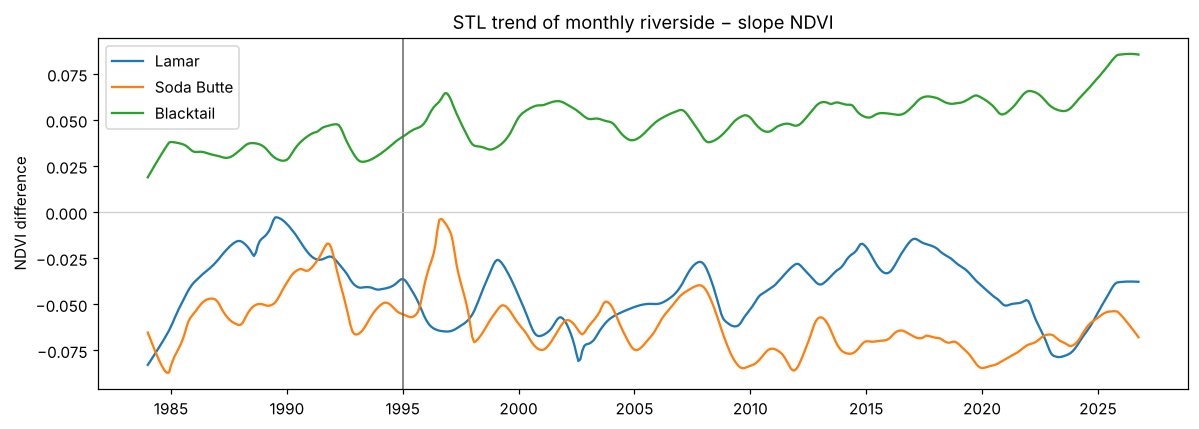

In [9]:
fig, ax = plt.subplots(figsize=(11, 4))
stl_rows = []
for p in PAIRS:
    m = paired[(paired.pair == p) & paired.month.between(4, 10)].set_index("date")["diff"].resample("MS").median()
    m = m.reindex(pd.date_range("1984-01-01", "2026-10-01", freq="MS")).interpolate(limit_direction="both")
    res = STL(m, period=12, robust=True).fit()
    ax.plot(res.trend.index, res.trend, color=COL[p], label=p)
    tr = res.trend.groupby(res.trend.index.year).mean()
    stl_rows.append({"pair": p, "trend 1985–1994 mean": round(tr.loc[1985:1994].mean(), 3),
                     "trend 2005–2014 mean": round(tr.loc[2005:2014].mean(), 3),
                     "trend 2015–2021 mean": round(tr.loc[2015:2021].mean(), 3)})
ax.axvline(pd.Timestamp("1995-01-01"), color="0.4", lw=1); ax.axhline(0, color="0.8", lw=0.8)
ax.set_title("STL trend of monthly riverside − slope NDVI"); ax.legend(); ax.set_ylabel("NDVI difference")
save(fig, "11_stl_trend")
pd.DataFrame(stl_rows).set_index("pair")

## 3. Does water limit willows more than elk do? (Q6)

Marshall, Hobbs & Cooper (2013) argued that willows on the northern range are held back by low water tables (streams cut down after beavers left), not only by elk browsing. Here: does the riverside − slope difference track **summer water** (the river's 7-day low flow in July–September, from notebook 12) or **elk numbers** (the corrected whole-herd count from Person 1, winter count labelled by the year it ends, so browsing that winter precedes that summer)? Bison are included because they also browse riparian plants.

Model, pooled over the three pairs with a separate intercept per pair, all predictors standardised (so coefficients compare directly: change in NDVI difference per 1 SD):

$$d_{p,y} = \alpha_p + \beta_W\,\text{lowflow}_y + \beta_E\,\log \text{elk}_y + \beta_B\,\log \text{bison}_y + \varepsilon$$

Elk and bison trend over the period, which risks a spurious fit, so the same model is also run **in first differences** (year-to-year changes). Caveat: the river gauge integrates a huge basin; it is an index of how wet the summer is, not the water table under these willows.

In [10]:
river = pd.read_csv(PROC / "river_annual_features.csv", index_col="Year")
master = pd.read_csv(ROOT.parent / "01_yellowstone_elk_wolves" / "data" / "processed" / "yellowstone_master_ts_flagged.csv", index_col="Year")   # Person 1 corrected master
drivers = pd.DataFrame({"lowflow": np.log(river["low7_summer_Q"]),
                        "log_elk": np.log(master["Elk_Count"]),
                        "log_bison": np.log(master["Bison_Count"]),
                        "elk_real": master["Elk_Count_imputed"] == 0})
dz = drivers[["lowflow", "log_elk", "log_bison"]].loc[1984:2025]
dz = (dz - dz.mean()) / dz.std()
dz["elk_real"] = drivers["elk_real"]
reg = ann.merge(dz, left_on="year", right_index=True).dropna(subset=["lowflow", "log_elk", "log_bison"])

def fit(data, formula):
    return smf.ols(formula, data=data).fit(cov_type="cluster", cov_kwds={"groups": data["year"]})

rows = []
specs = {"levels, all years": (reg, "diff ~ C(pair) + lowflow + log_elk + log_bison"),
         "levels, real elk counts only": (reg[reg.elk_real], "diff ~ C(pair) + lowflow + log_elk + log_bison"),
         "levels, water only": (reg, "diff ~ C(pair) + lowflow"),
         "levels, elk only": (reg, "diff ~ C(pair) + log_elk")}
fd = reg.sort_values(["pair", "year"]).copy()
for c in ["diff", "riverside", "slope", "lowflow", "log_elk", "log_bison"]:
    fd["d_" + c] = fd.groupby("pair")[c].diff()
fd = fd[fd.groupby("pair")["year"].diff() == 1].dropna(subset=["d_diff", "d_lowflow", "d_log_elk", "d_log_bison"])
specs["first differences"] = (fd, "d_diff ~ d_lowflow + d_log_elk + d_log_bison")
for name, (data, f) in specs.items():
    r = fit(data, f)
    for term in [t for t in r.params.index if "lowflow" in t or "elk" in t or "bison" in t]:
        rows.append({"model": name, "term": term.replace("d_", "Δ"), "coef": round(r.params[term], 4),
                     "CI low": round(r.conf_int().loc[term, 0], 4), "CI high": round(r.conf_int().loc[term, 1], 4),
                     "p": round(r.pvalues[term], 3), "n": int(r.nobs)})
water_elk = pd.DataFrame(rows)
water_elk.to_csv(TAB / "P2_water_vs_elk.csv", index=False)
water_elk

,model,term,coef,CI low,CI high,p,n
0,"levels, all years",lowflow,-0.0132,-0.0234,-0.0031,0.011,125
1,"levels, all years",log_elk,0.0079,-0.0098,0.0257,0.383,125
2,"levels, all years",log_bison,-0.0008,-0.0243,0.0228,0.948,125
3,"levels, real elk counts only",lowflow,-0.0117,-0.0231,-0.0003,0.044,102
4,"levels, real elk counts only",log_elk,0.0070,-0.0119,0.0259,0.466,102
5,"levels, real elk counts only",log_bison,0.0002,-0.0239,0.0243,0.987,102
6,"levels, water only",lowflow,-0.0133,-0.0212,-0.0054,0.001,125
7,"levels, elk only",log_elk,0.0088,-0.0003,0.0180,0.059,125
8,first differences,Δlowflow,-0.0097,-0.0179,-0.0015,0.020,122
9,first differences,Δlog_elk,-0.0447,-0.0766,-0.0127,0.006,122


In [11]:
per_pair = []
for p in PAIRS:
    r = fit(reg[reg.pair == p], "diff ~ lowflow + log_elk + log_bison")
    per_pair.append({"pair": p, **{f"{t} coef (p)": f"{r.params[t]:+.3f} ({r.pvalues[t]:.2f})" for t in ["lowflow", "log_elk", "log_bison"]}, "n": int(r.nobs)})
pd.DataFrame(per_pair).set_index("pair")

,lowflow coef (p),log_elk coef (p),log_bison coef (p),n
pair,,,,
Lamar,-0.019 (0.02),+0.007 (0.63),-0.007 (0.69),42
Soda Butte,-0.018 (0.02),+0.018 (0.21),-0.013 (0.44),42
Blacktail,-0.004 (0.25),-0.002 (0.78),+0.017 (0.04),41


Reading the tables: a positive `lowflow` coefficient means wetter summers make the riverside greener relative to the slope; a negative coefficient means the gap narrows. The pooled levels models fail the residual checks below, so the first-difference version is the one to read.

**Caution:** a narrowing gap does not say which side moved. It could be a browner riverside, a greener slope, or both sides greening with the slope gaining more. To find out, the next cell fits the same first-difference model to the riverside and the slope **separately**.

In [12]:
from statsmodels.stats.diagnostic import acorr_ljungbox as _lb, het_arch as _arch
rows, white = [], []
for y, label in [("d_riverside", "Streamside"), ("d_slope", "Hillside"), ("d_diff", "Gap (streamside − hillside)")]:
    r = fit(fd, f"{y} ~ d_lowflow + d_log_elk + d_log_bison")
    for t, name in [("d_lowflow", "summer low flow"), ("d_log_elk", "log elk"), ("d_log_bison", "log bison")]:
        rows.append({"driver rises": name, "outcome": label, "coef": round(r.params[t], 4),
                     "CI low": round(r.conf_int().loc[t, 0], 4), "CI high": round(r.conf_int().loc[t, 1], 4), "p": round(r.pvalues[t], 3)})
    e = pd.DataFrame({"pair": fd["pair"], "year": fd["year"], "e": r.resid}).sort_values(["pair", "year"])
    for p_, g in e.groupby("pair"):
        lbp = _lb(g["e"], lags=[5, 10]).lb_pvalue.values
        white.append({"outcome": label, "stream": p_, "Ljung–Box p lag 5": round(lbp[0], 3), "lag 10": round(lbp[1], 3),
                      "ARCH p": round(_arch(g["e"].values, nlags=2)[1], 3)})
by_side = pd.DataFrame(rows)
by_side.to_csv(TAB / "P2_water_vs_elk_by_side.csv", index=False)
print("Residual checks, one stream at a time in year order:")
print(pd.DataFrame(white).set_index(["outcome", "stream"]).to_string())
by_side.assign(cell=by_side.apply(lambda r: f"{r.coef:+.3f} (p = {r.p:.3f})", axis=1)).pivot(index="driver rises", columns="outcome", values="cell")[["Streamside", "Hillside", "Gap (streamside − hillside)"]]

Residual checks, one stream at a time in year order:
                                        Ljung–Box p lag 5  lag 10  ARCH p
outcome                     stream                                       
Streamside                  Blacktail               0.182   0.557   0.853
                            Lamar                   0.604   0.829   0.435
                            Soda Butte              0.135   0.416   0.938
Hillside                    Blacktail               0.591   0.773   0.434
                            Lamar                   0.103   0.410   0.574
                            Soda Butte              0.056   0.247   0.986
Gap (streamside − hillside) Blacktail               0.081   0.178   0.110
                            Lamar                   0.630   0.951   0.306
                            Soda Butte              0.157   0.139   0.338


outcome,Streamside,Hillside,Gap (streamside − hillside)
driver rises,,,
log bison,-0.049 (p = 0.002),-0.048 (p = 0.078),+0.004 (p = 0.888)
log elk,+0.046 (p = 0.006),+0.104 (p = 0.000),-0.045 (p = 0.006)
summer low flow,+0.028 (p = 0.000),+0.038 (p = 0.000),-0.010 (p = 0.020)


**Reading the side-by-side table.**

- **Water:** both sides are greener in wetter summers; the dry hillside gains more, so the gap narrows. Water matters for greenness everywhere, which is why this gap cannot isolate water-table limits on willows.
- **Elk:** in years when elk numbers rise, **both sides are greener**, the hillside by more. This is not a browsing signal. The likely explanation is that the same good conditions (mild winters, good growing seasons) help elk survive and plants grow; the data cannot separate that from any browsing effect.
- **Bison:** in years when bison rise, both sides are a little browner (clearly on the streamside, weakly on the hillside), so the gap does not move. A possible grazing effect, not tested further here.

### Granger causality: do past water, elk or bison help predict the riverside difference?

The regression above is about the *same* year. Granger causality asks a time-series question: once we know the riverside − slope difference's own past, do **past** values of low flow, elk or bison improve the prediction of it? "Granger-causes" means "helps predict", not "biologically causes".

Granger tests need stationary series, so each series is first checked with ADF (null: unit root) and KPSS (null: stationary). A series is used in levels if ADF rejects and KPSS does not; otherwise its first difference is used. Then, for each stream:

1. **Pairwise tests**, lags 1 and 2, in both directions. The reverse direction is a sanity check: riverside greenness cannot plausibly drive river flow or bison numbers, so a "significant" reverse result would warn of a spurious link.
2. **One VAR per stream** with all four series together (lag 1, as ~40 years cannot support more with four variables), testing each driver while holding the others fixed.

Elk counts include imputed years (Person 1's flags); with only ~40 years per stream, these tests have low power, so a non-significant result means "no evidence", not "no effect".

In [13]:
import contextlib, io
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.tsa.api import VAR
from statsmodels.tsa.stattools import adfuller, grangercausalitytests, kpss

def stat_tests(s):
    s = s.dropna()
    return adfuller(s, autolag="AIC")[1], kpss(s, regression="c", nlags="auto")[1]

raw_series = {f"veg diff, {p}": ann[ann.pair == p].set_index("year")["diff"] for p in PAIRS}
raw_series |= {c: drivers[c].loc[1984:2026] for c in ["lowflow", "log_elk", "log_bison"]}
rows, gc_series = [], {}
for name, s in raw_series.items():
    a, k = stat_tests(s)
    a1, k1 = stat_tests(s.diff())
    use_levels = a < 0.05 and k >= 0.05
    gc_series[name] = s if use_levels else s.diff()
    rows.append({"series": name, "ADF p (levels)": round(a, 3), "KPSS p (levels)": round(k, 3),
                 "ADF p (diff)": round(a1, 3), "KPSS p (diff)": round(k1, 3), "used in Granger": "levels" if use_levels else "first difference"})
gc_stationarity = pd.DataFrame(rows).set_index("series")
gc_stationarity.to_csv(TAB / "P2_granger_stationarity.csv")
gc_stationarity
# (KPSS p-values are capped at 0.01 and 0.10 by its lookup table.)

,ADF p (levels),KPSS p (levels),ADF p (diff),KPSS p (diff),used in Granger
series,,,,,
"veg diff, Lamar",0.000,0.100,0.0,0.100,levels
"veg diff, Soda Butte",0.009,0.019,0.0,0.100,first difference
"veg diff, Blacktail",0.885,0.012,0.0,0.100,first difference
lowflow,0.000,0.100,0.0,0.092,levels
log_elk,0.622,0.010,0.0,0.100,first difference
log_bison,0.939,0.010,0.0,0.100,first difference


In [14]:
label = {"lowflow": "summer low flow", "log_elk": "log elk", "log_bison": "log bison"}
rows = []
for p in PAIRS:
    veg = gc_series[f"veg diff, {p}"].rename("veg")
    for x in ["lowflow", "log_elk", "log_bison"]:
        d = pd.concat([veg, gc_series[x].rename("x")], axis=1).dropna()
        for target, cause, direction in [("veg", "x", f"{label[x]} → veg"), ("x", "veg", f"veg → {label[x]}")]:
            with contextlib.redirect_stdout(io.StringIO()):   # older statsmodels prints every test
                out = grangercausalitytests(d[[target, cause]], maxlag=2)
            rows.append({"stream": p, "direction": direction, "lag 1 p": round(out[1][0]["ssr_ftest"][1], 3),
                         "lag 2 p": round(out[2][0]["ssr_ftest"][1], 3), "n": len(d)})
granger_pw = pd.DataFrame(rows)
granger_pw.to_csv(TAB / "P2_granger_pairwise.csv", index=False)
granger_pw.pivot(index="direction", columns="stream", values="lag 1 p").round(3)

stream,Blacktail,Lamar,Soda Butte
direction,,,
log bison → veg,0.830,0.874,0.638
log elk → veg,0.288,0.203,0.563
summer low flow → veg,0.482,0.720,0.843
veg → log bison,0.387,0.651,0.390
veg → log elk,0.991,0.151,0.480
veg → summer low flow,0.712,0.698,0.396


In [15]:
granger_pw.set_index(["stream", "direction"])

lag 1 p  lag 2 p   n
stream     direction                                  
Lamar      summer low flow → veg    0.720    0.973  43
           veg → summer low flow    0.698    0.760  43
           log elk → veg            0.203    0.519  41
           veg → log elk            0.151    0.105  41
           log bison → veg          0.874    0.789  41
           veg → log bison          0.651    0.058  41
Soda Butte summer low flow → veg    0.843    0.680  42
           veg → summer low flow    0.396    0.550  42
           log elk → veg            0.563    0.311  41
           veg → log elk            0.480    0.361  41
           log bison → veg          0.638    0.415  41
           veg → log bison          0.390    0.633  41
Blacktail  summer low flow → veg    0.482    0.262  41
           veg → summer low flow    0.712    0.781  41
           log elk → veg            0.288    0.306  40
           veg → log elk            0.991    0.850  40
           log bison → veg          0.830    0.901  40
           veg → log bison          0.387    0.452  40

In [16]:
rows, var_white = [], []
for p in PAIRS:
    V = pd.concat([gc_series[f"veg diff, {p}"].rename("veg")] + [gc_series[x].rename(x) for x in ["lowflow", "log_elk", "log_bison"]], axis=1).dropna()
    res = VAR(V).fit(1)
    for x in ["lowflow", "log_elk", "log_bison"]:
        t_fwd = res.test_causality("veg", [x], kind="f")
        t_rev = res.test_causality(x, ["veg"], kind="f")
        rows.append({"stream": p, "driver": label[x], "driver → veg p": round(t_fwd.pvalue, 3),
                     "veg → driver p": round(t_rev.pvalue, 3), "n": int(res.nobs)})
    w = res.test_whiteness(nlags=8, adjusted=True)
    var_white.append({"stream": p, "Portmanteau (multivariate Ljung–Box) p, 8 lags": round(w.pvalue, 3),
                      **{f"Ljung–Box p, {c} eq. (lag 8)": round(acorr_ljungbox(res.resid[c], lags=[8]).lb_pvalue.iloc[0], 3) for c in V.columns}})
granger_var = pd.DataFrame(rows)
granger_var.to_csv(TAB / "P2_granger_var.csv", index=False)
var_white = pd.DataFrame(var_white).set_index("stream")
granger_var

,stream,driver,driver → veg p,veg → driver p,n
0,Lamar,summer low flow,0.573,0.611,40
1,Lamar,log elk,0.198,0.104,40
2,Lamar,log bison,0.870,0.608,40
3,Soda Butte,summer low flow,0.874,0.149,40
4,Soda Butte,log elk,0.495,0.319,40
5,Soda Butte,log bison,0.521,0.398,40
6,Blacktail,summer low flow,0.493,0.565,39
7,Blacktail,log elk,0.312,0.977,39
8,Blacktail,log bison,0.891,0.395,39


The VAR's residuals must themselves be white noise for its Granger tests to be valid. The Portmanteau test is the multivariate version of Ljung–Box (null: no autocorrelation left in any equation, up to lag 8); p > 0.05 means the VAR(1) has captured the dynamics.

In [17]:
var_white

,"Portmanteau (multivariate Ljung–Box) p, 8 lags","Ljung–Box p, veg eq. (lag 8)","Ljung–Box p, lowflow eq. (lag 8)","Ljung–Box p, log_elk eq. (lag 8)","Ljung–Box p, log_bison eq. (lag 8)"
stream,,,,,
Lamar,0.600,0.806,0.581,0.598,0.917
Soda Butte,0.475,0.094,0.583,0.650,0.858
Blacktail,0.759,0.288,0.649,0.719,0.979


### Residual checks: are the errors white noise?

Every regression in sections 2 and 3 assumes that what is left after the model is white noise: no autocorrelation (Ljung–Box test, lags 5 and 10, null = white noise) and constant variance (ARCH LM test, 2 lags). The intervention and regression models already use autocorrelation-robust standard errors (Newey–West or clustered by year), so mild autocorrelation would not invalidate their p-values, but it should still be reported.

Pooled models stack three streams, so their residuals are checked **one stream at a time, in year order** (stacking different streams end to end is not one time series).

In [18]:
def resid_check(e, model, stream):
    e = pd.Series(np.asarray(e, float)).dropna()
    lb = acorr_ljungbox(e, lags=[5, 10]).lb_pvalue.values
    arch_p = het_arch(e.values, nlags=2)[1]
    return {"model": model, "stream": stream, "n": len(e), "Ljung–Box p lag 5": round(lb[0], 3),
            "Ljung–Box p lag 10": round(lb[1], 3), "ARCH p": round(arch_p, 3),
            "white noise (all p > 0.05)": bool(min(lb[0], lb[1], arch_p) > 0.05)}

def by_stream(r, data, model):
    e = pd.DataFrame({"pair": data["pair"], "year": data["year"], "e": r.resid}).sort_values(["pair", "year"])
    return [resid_check(g["e"], model, p) for p, g in e.groupby("pair")]

rows = []
for p in PAIRS:
    d = ann[ann.pair == p].sort_values("year")
    rows.append(resid_check(intervention(d).resid, "intervention (step + ramp at 1995)", p))
    d2 = d.assign(t=d.year - 1995, post=(d.year >= 1995).astype(int), OLI=(d.year >= 2013).astype(int))
    d2["ramp"] = d2["t"] * d2["post"]
    rows.append(resid_check(smf.ols("diff ~ t + post + ramp + OLI", data=d2).fit().resid, "intervention + 2013 sensor dummy", p))
d = ann.assign(t=ann.year - 1995, post=(ann.year >= 1995).astype(int)); d["ramp"] = d["t"] * d["post"]
rows += by_stream(smf.ols("diff ~ C(pair) + t + post + ramp", data=d).fit(), d, "intervention, pooled")
for name, (data, f) in specs.items():
    rows += by_stream(smf.ols(f, data=data).fit(), data, f"water vs elk: {name}")
for p in PAIRS:
    data = reg[reg.pair == p].sort_values("year")
    rows.append(resid_check(smf.ols("diff ~ lowflow + log_elk + log_bison", data=data).fit().resid, "water vs elk, one stream", p))
resid11 = pd.DataFrame(rows)
resid11.to_csv(TAB / "P2_residual_checks_veg.csv", index=False)
print(f"{resid11['white noise (all p > 0.05)'].sum()} of {len(resid11)} model × stream residual series pass all three tests")
resid11

16 of 27 model × stream residual series pass all three tests


,model,stream,n,Ljung–Box p lag 5,Ljung–Box p lag 10,ARCH p,white noise (all p > 0.05)
0,intervention (step + ramp at 1995),Lamar,43,0.706,0.949,0.665,True
1,intervention + 2013 sensor dummy,Lamar,43,0.672,0.937,0.654,True
2,intervention (step + ramp at 1995),Soda Butte,43,0.034,0.111,0.277,False
3,intervention + 2013 sensor dummy,Soda Butte,43,0.029,0.107,0.250,False
4,intervention (step + ramp at 1995),Blacktail,42,0.154,0.227,0.793,True
5,intervention + 2013 sensor dummy,Blacktail,42,0.162,0.233,0.796,True
6,"intervention, pooled",Blacktail,42,0.000,0.000,0.004,False
7,"intervention, pooled",Lamar,43,0.846,0.975,0.610,True
8,"intervention, pooled",Soda Butte,43,0.027,0.179,0.233,False
9,"water vs elk: levels, all years",Blacktail,41,0.000,0.000,0.173,False


**Fixing the failures.** Where residuals are autocorrelated, the standard remedy is to model that autocorrelation: regression with AR(1) errors, $d_y = a + b\,t + c\,\text{post} + e\,\text{ramp} + u_y$, $u_y = \phi u_{y-1} + \varepsilon_y$ (an ARIMAX(1,0,0)). If the step and ramp estimates barely move and the new residuals pass, the conclusions above stand.

In [19]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
rows = []
for p in PAIRS:
    d = ann[ann.pair == p].sort_values("year").assign(t=lambda x: x.year - 1995, post=lambda x: (x.year >= 1995).astype(float))
    d["ramp"] = d["t"] * d["post"]
    r = SARIMAX(d["diff"].values, exog=d[["t", "post", "ramp"]].values, order=(1, 0, 0), trend="c").fit(disp=False)
    names = dict(zip(r.model.param_names, r.params)); pv = dict(zip(r.model.param_names, r.pvalues))
    e = r.resid[1:]
    rows.append({"stream": p, "AR(1) φ (p)": f"{names['ar.L1']:+.2f} ({pv['ar.L1']:.2f})",
                 "step at 1995 (p)": f"{names['x2']:+.3f} ({pv['x2']:.2f})",
                 "trend change /yr (p)": f"{names['x3']:+.4f} ({pv['x3']:.2f})",
                 "Ljung–Box p lag 5": round(acorr_ljungbox(e, lags=[5]).lb_pvalue.iloc[0], 3),
                 "Ljung–Box p lag 10": round(acorr_ljungbox(e, lags=[10]).lb_pvalue.iloc[0], 3)})
interv_ar1 = pd.DataFrame(rows).set_index("stream")
interv_ar1.to_csv(TAB / "P2_veg_intervention_ar1.csv")
interv_ar1

,AR(1) φ (p),step at 1995 (p),trend change /yr (p),Ljung–Box p lag 5,Ljung–Box p lag 10
stream,,,,,
Lamar,+0.06 (0.68),-0.066 (0.28),-0.0055 (0.39),0.819,0.965
Soda Butte,+0.39 (0.02),-0.001 (0.99),+0.0011 (0.92),0.228,0.440
Blacktail,-0.07 (0.67),-0.012 (0.43),+0.0042 (0.04),0.150,0.230


**Reading the residual checks.**

- **Single-stream models pass** (intervention models and the per-stream water vs elk regressions), apart from a marginal Ljung–Box failure at lag 5 for the Soda Butte intervention model. Refitting all three intervention models with AR(1) errors gives white residuals everywhere, and:
  - **Soda Butte:** φ = 0.39 is significant, so the AR(1) version is the right model; the 1995 step and ramp stay near zero, as before.
  - **Lamar:** φ is near zero (the OLS residuals were already white), but the 1995 step loses significance (p = 0.03 with Newey–West errors, 0.28 with AR(1) errors). Lamar's step down is fragile, which fits the flood explanation in the summary rather than a wolf effect.
  - **Blacktail:** the post-1995 rise in trend becomes significant (+0.004 NDVI per year, p = 0.04), agreeing with the Mann–Kendall result in section 2.
- **The pooled models in levels fail for Blacktail and Soda Butte.** Forcing one set of slopes on all three streams leaves each stream's own slow drift (for example, Blacktail's post-1995 rise) in the residuals. Their p-values use clustered or Newey–West errors, but the coefficients should be read through the **first-difference model and the per-stream fits, which both pass**.
- **Granger causality: no driver helps predict the riverside difference one or two years ahead**, in any stream, pairwise or in the four-variable VAR, and the reverse-direction sanity checks are also null. The VARs' residuals pass the multivariate Portmanteau test, so this is not a model-fit problem. Whatever effects elk and water have on riverside greenness show up **in the same year** (section 3's first-difference model), not with a lag that annual data can detect.

## 4. Does spring green-up follow snowmelt? (Q3)

For each polygon and year, fit a **double-logistic** curve to the March–November NDVI points (mathematical modelling of the seasonal cycle):

$$\text{NDVI}(t) = v_{min} + (v_{max}-v_{min})\left[\frac{1}{1+e^{-k_1(t-\text{SOS})}} - \frac{1}{1+e^{-k_2(t-\text{EOS})}}\right]$$

SOS (start of season) is the green-up date. A fit is kept only if the year has at least 6 points including at least 2 before day 170, the curve converges, and SOS falls between day 90 and 200. The slope polygons are used (riverside greenness is also driven by flooding). Then compare green-up with the snow melt-out anomaly (three SNOTEL stations) and the river's centre of timing.

In [20]:
def dlogistic(t, vmin, vmax, sos, k1, eos, k2):
    return vmin + (vmax - vmin) * (1 / (1 + np.exp(-k1 * (t - sos))) - 1 / (1 + np.exp(-k2 * (t - eos))))

def fit_sos(g):
    g = g[g.doy.between(60, 330)]
    if len(g) < 6 or (g.doy < 170).sum() < 2:
        return np.nan
    p0 = [g.ndvi.min(), g.ndvi.max(), 150, 0.08, 260, 0.05]
    bounds = ([-0.2, 0.1, 80, 0.01, 200, 0.01], [0.4, 1.0, 220, 0.5, 330, 0.5])
    try:
        p, _ = curve_fit(dlogistic, g.doy, g.ndvi, p0=p0, bounds=bounds, maxfev=20000)
    except Exception:
        return np.nan
    return p[2] if 90 <= p[2] <= 200 else np.nan

slopes = long[long.side == "slope"]
sos = slopes.groupby(["pair", "year"]).apply(fit_sos).unstack(0)
sos["mean SOS"] = sos[PAIRS].mean(axis=1)
sos["n pairs"] = sos[PAIRS].notna().sum(axis=1)
sos.to_csv(TAB / "P2_greenup_sos.csv")
print("Years with a usable green-up date, by slope polygon:", sos[PAIRS].notna().sum().to_dict())
sev = pd.read_csv(PROC / "winter_severity_index.csv", index_col="Year")
g = pd.concat([sos["mean SOS"], sev["Melt_out_anom_days"], river["CT_dowy"]], axis=1).loc[1984:2026].dropna()
r1 = sm.OLS(g["mean SOS"], sm.add_constant(g[["Melt_out_anom_days"]])).fit(cov_type="HAC", cov_kwds={"maxlags": 2})
r2 = sm.OLS(g["mean SOS"], sm.add_constant(g[["CT_dowy"]])).fit(cov_type="HAC", cov_kwds={"maxlags": 2})
greenup = pd.DataFrame([
    {"predictor": "snow melt-out anomaly (days)", "days of green-up per day": round(r1.params.iloc[1], 2),
     "CI": f"{r1.conf_int().iloc[1, 0]:.2f} to {r1.conf_int().iloc[1, 1]:.2f}", "p": round(r1.pvalues.iloc[1], 4), "R2": round(r1.rsquared, 2), "n": int(r1.nobs)},
    {"predictor": "river centre of timing (day of WY)", "days of green-up per day": round(r2.params.iloc[1], 2),
     "CI": f"{r2.conf_int().iloc[1, 0]:.2f} to {r2.conf_int().iloc[1, 1]:.2f}", "p": round(r2.pvalues.iloc[1], 4), "R2": round(r2.rsquared, 2), "n": int(r2.nobs)}])
greenup.to_csv(TAB / "P2_greenup_vs_snow.csv", index=False)
print(pd.DataFrame([trend(sos["mean SOS"], "green-up date (mean of slope polygons)")]).set_index("series").to_string())
greenup

Years with a usable green-up date, by slope polygon: {'Lamar': 34, 'Soda Butte': 34, 'Blacktail': 35}
                                            years   n  Sen slope per decade    MK p  MK p (autocorr-corrected) direction
series                                                                                                                  
green-up date (mean of slope polygons)  1986–2026  37                0.2023  0.8856                     0.8856  no trend


,predictor,days of green-up per day,CI,p,R2,n
0,snow melt-out anomaly (days),0.54,0.28 to 0.80,0.0001,0.27,37
1,river centre of timing (day of WY),0.88,0.58 to 1.17,0.0000,0.45,37


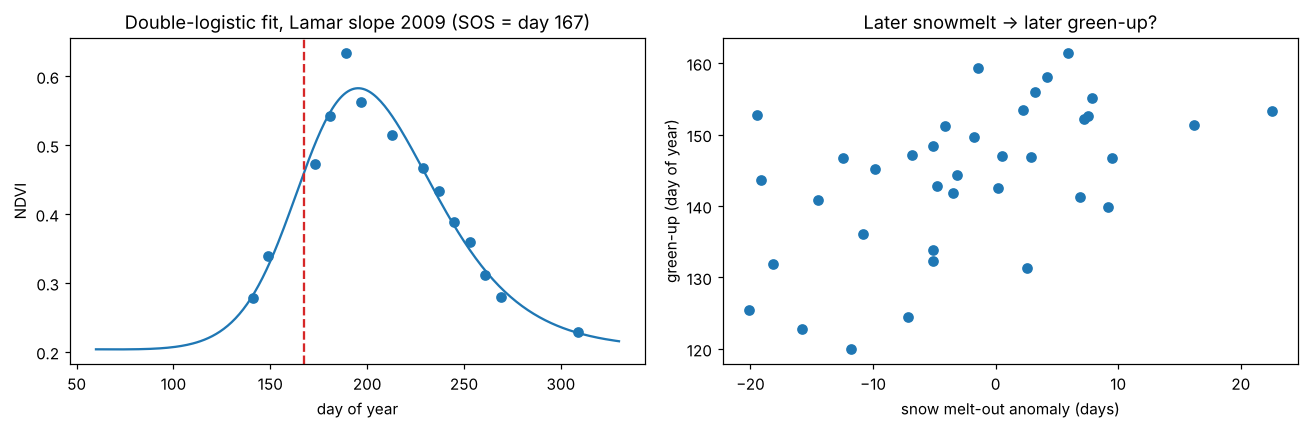

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ex_year = int(sos["Lamar"].dropna().index[len(sos["Lamar"].dropna()) // 2])
gx = slopes[(slopes.pair == "Lamar") & (slopes.year == ex_year) & slopes.doy.between(60, 330)]
p, _ = curve_fit(dlogistic, gx.doy, gx.ndvi, p0=[gx.ndvi.min(), gx.ndvi.max(), 150, 0.08, 260, 0.05],
                 bounds=([-0.2, 0.1, 80, 0.01, 200, 0.01], [0.4, 1.0, 220, 0.5, 330, 0.5]), maxfev=20000)
tt = np.arange(60, 331)
ax[0].scatter(gx.doy, gx.ndvi, color="C0"); ax[0].plot(tt, dlogistic(tt, *p), "C0-")
ax[0].axvline(p[2], color="C3", ls="--"); ax[0].set_title(f"Double-logistic fit, Lamar slope {ex_year} (SOS = day {p[2]:.0f})")
ax[0].set_xlabel("day of year"); ax[0].set_ylabel("NDVI")
ax[1].scatter(g["Melt_out_anom_days"], g["mean SOS"])
ax[1].set_xlabel("snow melt-out anomaly (days)"); ax[1].set_ylabel("green-up (day of year)")
ax[1].set_title("Later snowmelt → later green-up?")
save(fig, "12_greenup")

## 5. What did the June 2022 flood do to the riverside?

The record flood (notebook 12) scoured floodplains along the Lamar River and Soda Butte Creek. If it removed riparian vegetation, the riverside − slope difference should drop in summer 2022 and then recover. Blacktail Deer Creek, on the other side of the range, is a comparison.

In [22]:
rows = []
for p in PAIRS:
    s = ann[ann.pair == p].set_index("year")["diff"]
    base = s.loc[2017:2021]
    rows.append({"pair": p, "2017–2021 mean": round(base.mean(), 3), "2017–2021 SD": round(base.std(), 3),
                 "2022": round(s.get(2022, np.nan), 3), "change in SDs": round((s.get(2022, np.nan) - base.mean()) / base.std(), 1),
                 "2023": round(s.get(2023, np.nan), 3), "2024": round(s.get(2024, np.nan), 3),
                 "2025": round(s.get(2025, np.nan), 3), "2026": round(s.get(2026, np.nan), 3)})
flood = pd.DataFrame(rows).set_index("pair")
flood.to_csv(TAB / "P2_flood_vegetation.csv")
flood

,2017–2021 mean,2017–2021 SD,2022,change in SDs,2023,2024,2025,2026
pair,,,,,,,,
Lamar,-0.047,0.029,-0.218,-5.9,-0.126,-0.039,-0.020,0.005
Soda Butte,-0.137,0.037,-0.228,-2.5,-0.193,-0.074,-0.054,-0.030
Blacktail,0.093,0.009,0.064,-3.3,0.083,0.112,0.115,0.109


## 6. Summary (results as run on 20 November 2026)

1. **Riverside vs slope after 1995 (Q1): the answer depends on the stream.**
   - **Blacktail Deer Creek** (narrow, willow-lined, the creek Beschta & Ripple studied): the riverside has become greener relative to the slope since wolves returned, about +0.026 NDVI per decade over 1996–2026 (p < 0.001), with a break in 2007. The rise is already present within the Landsat 5/7 era (1996–2012), so it is not a sensor artefact. It is gradual, not a step at 1995, which fits willows slowly escaping browsing.
   - **Lamar River and Soda Butte Creek** (wide, braided, gravel-bed rivers): no greening. Both differences *fall* over 1984–2026, and Lamar even shows a step down at 1995 (significant with Newey–West errors, not with AR(1) errors). That step is almost certainly floods, not wolves: 1996 and 1997 had the 4th and 3rd largest river peaks in 116 years (notebook 12), and the difference dropped sharply in 1997 on both braided rivers, just as it did after the record 2022 flood. The wolf reintroduction and two major floods happened within two years of each other, which is a real confound for any before/after-1995 comparison. In these channels the riverside polygon is dominated by gravel, water and floods, so channel dynamics swamp any willow signal; this is also where Marshall et al. (2013) found incised channels and low water tables blocking willow recovery.
   - Pooled over the three streams, no 1995 effect.
2. **Water vs elk (Q6): not the simple "water limits willows" signal.** Wetter late summers go with a *smaller* riverside − slope difference, consistently across models. The likely reason is the design itself: in wet summers the upland slopes green up strongly while the riverside, which always has water, changes less (and high flow also covers more gravel with water). So this metric cannot isolate water-table limitation; a groundwater or channel-incision measure would be needed. Elk levels show no relationship. In first differences the gap narrows when elk increase (p = 0.006), but fitting each side separately shows both riverside and slope are *greener* in those years, the slope by more: a shared good-year effect, not a browsing signal. Bison years are slightly browner on both sides.
3. **Green-up (Q3):** green-up follows the river's snowmelt timing closely (≈0.9 days later per day of later melt runoff, R² = 0.45) and SNOTEL melt-out (R² = 0.27). Green-up dates show no trend, even though river timing has moved earlier (notebook 12), probably because the slopes sit lower than the snowpack that drives the river.
4. **Granger causality and residuals.** No driver (summer low flow, elk, bison) Granger-causes the riverside difference at lags 1–2 in any stream, pairwise or in a four-variable VAR, and the VARs' residuals pass the Portmanteau whiteness test. The elk and water links in point 2 are same-year, not lagged. Residuals of every single-stream model and of the first-difference model are white noise; the pooled levels models are not (stream-specific drift left over), which is why the first-difference results are the ones to trust.
5. **2022 flood:** the riverside − slope difference collapsed in summer 2022 on Lamar (about 6 SD below 2017–2021) and Soda Butte (2.5 SD), and recovered over 2023–2026. Part of the drop is slopes greening in a wet year (Blacktail also dipped), but Lamar's riverside NDVI fell in absolute terms, consistent with flood scour.

**Overall:** satellite evidence supports a riparian recovery on the small willow-lined creek where the cascade was originally reported, but not on the big braided rivers, where floods and channel form dominate. That middle position matches the recent literature: wolves may help, but stream form and water decide where willows can come back.

Caveats: 30 m pixels mix willows with gravel, grass and water; only 11 pre-wolf years (Landsat starts 1984); polygons are hand-drawn on present-day imagery and channels move; partial-cloud dates dropped; elk counts include imputed years (sensitivity run included); the river gauge is a basin-wide water index, not the local water table; the 1988 fires burned parts of the northern range, so vegetation was also recovering from fire in the late 1980s.

In [23]:
print(veg_trends[["Sen slope per decade", "MK p (autocorr-corrected)"]].to_string()); print()
print(interv[interv.term != "pre-1995 trend / yr"].to_string(index=False)); print()
print(breaks.to_string()); print()
print(sensor_check.to_string()); print()
print(water_elk.to_string(index=False)); print()
print(greenup.to_string(index=False)); print()
print(flood.to_string())

                       Sen slope per decade  MK p (autocorr-corrected)
series                                                                
Lamar: 1984–2026                    -0.0136                     0.0180
Lamar: 1984–1994                    -0.0290                        NaN
Lamar: 1996–2026                     0.0077                     0.2767
Soda Butte: 1984–2026               -0.0273                     0.0091
Soda Butte: 1984–1994               -0.0072                     0.8763
Soda Butte: 1996–2026               -0.0157                     0.3242
Blacktail: 1984–2026                 0.0176                     0.0000
Blacktail: 1984–1994                -0.0087                     0.5915
Blacktail: 1996–2026                 0.0255                     0.0000

                 pair                            term    coef  CI low  CI high     p   n
                Lamar                    step at 1995 -0.0661 -0.1271  -0.0051 0.034  43
                Lamar change in trend af